In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

In [2]:
A = np.array([[1,0],[0,-2]])
print(A)

[[ 1  0]
 [ 0 -2]]


In [3]:
results = la.eig(A)

In [4]:
print(results[0])

[ 1.+0.j -2.+0.j]


In [5]:
print(results[1])

[[1. 0.]
 [0. 1.]]


In [6]:
eigvals, eigvecs = la.eig(A)
print(eigvals)

[ 1.+0.j -2.+0.j]


In [7]:
print(eigvecs)

[[1. 0.]
 [0. 1.]]


In [8]:
eigvals = eigvals.real
print(eigvals)

[ 1. -2.]


In [9]:
lambda1 = eigvals[1]
print(lambda1)

-2.0


In [10]:
v1 = eigvecs[:,1].reshape(2,1)
print(v1)

[[0.]
 [1.]]


In [11]:
A @ v1

array([[ 0.],
       [-2.]])

In [12]:
lambda1 * v1

array([[-0.],
       [-2.]])

In [13]:
n = 4
P = np.random.randint(0,10,(n,n))
print(P)

[[9 4 4 8]
 [2 8 6 8]
 [4 1 1 4]
 [6 6 2 7]]


In [14]:
S = P @ P.T
print(S)

[[177 138  76 142]
 [138 168  54 128]
 [ 76  54  34  60]
 [142 128  60 125]]


In [15]:
evals, evecs = la.eig(S)
print(evals)

[458.76933554+0.j  40.16438454+0.j   4.36144383+0.j   0.70483609+0.j]


In [16]:
evals = evals.real
print(evals)

[458.76933554  40.16438454   4.36144383   0.70483609]


In [17]:
print(evecs)

[[ 0.60045368  0.51359236 -0.44801529  0.41828288]
 [ 0.55816261 -0.78578599 -0.24670344 -0.10065922]
 [ 0.25108752  0.33244016 -0.12329248 -0.90068727]
 [ 0.5146503   0.09081189  0.85042265  0.06057716]]


In [18]:
v1 = evecs[:,0] # A primeira coluna é o primeiro autovetor
print(v1)

[0.60045368 0.55816261 0.25108752 0.5146503 ]


In [19]:
v2 = evecs[:,1] # A segunda coluna é o segundo autovetor
print(v2)

[ 0.51359236 -0.78578599  0.33244016  0.09081189]


In [20]:
v1 @ v2

np.float64(4.996003610813204e-16)

In [21]:
np.round(evecs.T @ evecs, 10)

array([[ 1.,  0., -0., -0.],
       [ 0.,  1., -0.,  0.],
       [-0., -0.,  1.,  0.],
       [-0.,  0.,  0.,  1.]])

In [22]:
evals, evecs = la.eigh(S)
print(evals)

[  0.70483609   4.36144383  40.16438454 458.76933554]


In [23]:
theta = np.pi/6
R = np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
evals, evecs = la.eig(R)
print("Autovalores:", evals)
print("Módulos:", np.abs(evals))
print("Argumentos (graus):", np.degrees(np.angle(evals)))

Autovalores: [0.8660254+0.5j 0.8660254-0.5j]
Módulos: [1. 1.]
Argumentos (graus): [ 30. -30.]


In [24]:
P = np.array([[1,1],[1,-1]])
print(P)

[[ 1  1]
 [ 1 -1]]


In [25]:
D = np.diag((3,1))
print(D)

[[3 0]
 [0 1]]


In [26]:
M = P @ D @ la.inv(P)
print(M)

[[2. 1.]
 [1. 2.]]


In [27]:
evals, evecs = la.eig(M)
print(evals)

[3.+0.j 1.+0.j]


In [28]:
print(evecs)

[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [29]:
Pinv = la.inv(P)

In [30]:
k = 20

In [31]:
%%timeit
result = M.copy()
for _ in range(1,k):
    result = result @ M

9.82 µs ± 337 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


In [32]:
%%timeit
P @ D**k @ Pinv     # D**k eleva cada elemento a k: funciona porque D é diagonal

1.57 µs ± 23.1 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [33]:
def potencias(A,x0,tol=1e-10,maxit=1000):
    """Método das potências: retorna (autovalor dominante, autovetor, número de iterações)."""
    x = np.array(x0,dtype=float)
    x = x/la.norm(x)
    lam = x @ A @ x
    for k in range(1,maxit+1):
        y = A @ x
        x = y/la.norm(y)
        lam_novo = x @ A @ x
        if abs(lam_novo - lam) < tol:
            return lam_novo, x, k
        lam = lam_novo
    print("Atenção: o método não convergiu.")
    return lam, x, maxit

In [34]:
A = np.array([[2,1,0],[1,3,1],[0,1,4]])
lam, v, k = potencias(A,[1,1,1])
print("Método das potências:", lam, "em", k, "iterações")
print("la.eigh:             ", la.eigh(A)[0])

Método das potências: 4.73205080753942 em 25 iterações
la.eigh:              [1.26794919 3.         4.73205081]


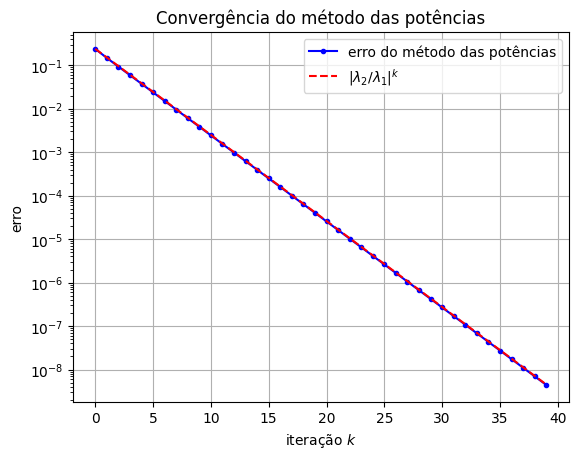

In [35]:
evals, evecs = la.eigh(A)
v1 = evecs[:,-1]                    # autovetor do maior autovalor
razao = abs(evals[-2]/evals[-1])
x = np.array([1.,1.,1.]); x = x/la.norm(x)
erros = []
for k in range(40):
    x = A @ x; x = x/la.norm(x)
    erros.append(min(la.norm(x - v1), la.norm(x + v1)))   # o autovetor é definido a menos de sinal

plt.semilogy(erros,'b.-',label="erro do método das potências")
plt.semilogy(erros[0]*razao**np.arange(40),'r--',label=r"$|\lambda_2/\lambda_1|^k$")
plt.xlabel("iteração $k$"), plt.ylabel("erro"), plt.grid(True), plt.legend()
plt.title("Convergência do método das potências")
plt.show()